# PROJETO DE ANÁLISE DE DADOS - GRUPO 3
## Painel das Escolas do Futuro de Goiás

**Integrantes:** Jacob Almeida, Carlos Henrique, Junio e Jhullyana  
**Tema:** Educação — qualificação profissional oferecida pelas Escolas do Futuro de Goiás.

Este notebook usa a base `dados_tratados.csv`.

## 1. Problema

Não está claro como a oferta de turmas, vagas e matrículas das Escolas do Futuro de Goiás se distribui entre escolas, categorias e cursos, nem se as vagas ofertadas estão sendo preenchidas e como isso mudou ao longo dos anos. Sem essa visão, é difícil avaliar se a oferta de cursos atende à procura.

## 2. Pergunta principal

**Como as turmas, as vagas e as matrículas dos cursos das Escolas do Futuro de Goiás estão distribuídas entre escolas, categorias e cursos, e como isso mudou de 2022 a 2025?**

## 3. Objetivos

### Objetivo geral
Analisar a distribuição das turmas, das vagas e das matrículas dos cursos das Escolas do Futuro de Goiás entre escolas, categorias e cursos, no período de 2022 a 2025.

### Objetivos específicos
1. Identificar a quantidade de turmas, vagas e matrículas por escola, categoria e curso.
2. Comparar a taxa de ocupação das vagas entre escolas e cursos.
3. Identificar os cursos e as escolas com maior e menor número de matrículas.
4. Verificar a evolução do número de turmas e de matrículas ao longo dos anos de 2022 a 2025.
5. Observar a proporção de turmas por status, turno e modalidade.

### Perguntas que serão investigadas
- Qual curso e qual categoria possuem mais matrículas?
- Qual escola possui mais matrículas e qual possui menos?
- Qual é a taxa de ocupação das vagas e onde ela é menor?
- Existe diferença de ocupação entre turnos e modalidades?
- Como o número de turmas e de matrículas mudou ao longo do tempo?
- Qual categoria apresentou maior crescimento no período?

## 4. Importação das bibliotecas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 5. Carregamento dos dados
No Google Colab, envie o arquivo `dados_tratados.csv` na área de arquivos. Se o arquivo estiver na mesma pasta do notebook, o código abaixo funciona diretamente.

In [2]:
try:
    dados = pd.read_csv("dados_tratados.csv", sep=None, engine="python", encoding="utf-8")
except FileNotFoundError:
    # Se estiver usando o Google Colab, esta parte permite enviar o CSV
    from google.colab import files
    arquivo_enviado = files.upload()
    nome_arquivo = next(iter(arquivo_enviado))
    dados = pd.read_csv(nome_arquivo, sep=None, engine="python", encoding="utf-8")

# Mostrar as primeiras linhas para conferir se o arquivo foi carregado
dados.head()

,id_turma,turma,escola,projeto,categoria,curso,modalidade,qtde_vagas,turno,data_inicio,data_fim,status_turma,carga_horaria,matriculas_turma,matriculas_aptas
0,5575,QP-ABF-PMU-V2-2022,EM ARTES BASILEU FRANÇA,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Qualificação,PERFORMANCE MUSICAL,PRESENCIAL,23,VESPERTINO,14/02/2022,28/06/2024,Concluído,126.0,23,11.0
1,5535,TEC-ABF-MIM-N1-2022,EM ARTES BASILEU FRANÇA,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Técnico,TÉCNICO DE NÍVEL MEDIO EM INSTRUMENTO MUSICAL,PRESENCIAL,22,NOTURNO,17/02/2020,30/06/2024,Concluído,267.0,17,11.0
2,5534,TEC-ABF-MIM-V1-2022,EM ARTES BASILEU FRANÇA,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Técnico,TÉCNICO DE NÍVEL MEDIO EM INSTRUMENTO MUSICAL,PRESENCIAL,22,VESPERTINO,26/05/2021,14/08/2024,Concluído,235.0,17,15.0
3,5472,CP-JLB-MKTDG-ONL-N3-2022,JOSÉ LUIZ BITTENCOURT,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Capacitação,MARKETING DIGITAL - ONL,PRESENCIAL,34,NOTURNO,29/06/2022,13/07/2022,Concluído,23.0,34,25.0
4,5470,QP-SLLKO-QPIMNI-N1-2022,SARAH LUÍSA LEMOS KUBITSCHEK DE OLIVEIRA,05 - ROJG - REDE DE ORQUESTRA JOVEM DE GOIÁS,Qualificação,QUALIFICAÇÃO PROFISSIONAL EM INSTRUMENTO MUSIC...,PRESENCIAL,28,NOTURNO,20/06/2022,23/12/2022,Concluído,134.0,28,28.0


## 6. Conhecendo a base
Vamos verificar o tamanho da base, os nomes das colunas, os tipos de dados e se existem valores vazios.

In [3]:
print("Quantidade de linhas e colunas:")
print(dados.shape)

print("\\nNomes das colunas:")
print(dados.columns.tolist())

print("\\nTipos de dados:")
print(dados.dtypes)

print("\\nValores vazios por coluna:")
print(dados.isnull().sum())

print("\\nPrimeiras linhas da base:")
display(dados.head())

Quantidade de linhas e colunas:
(5157, 15)
\nNomes das colunas:
['id_turma', 'turma', 'escola', 'projeto', 'categoria', 'curso', 'modalidade', 'qtde_vagas', 'turno', 'data_inicio', 'data_fim', 'status_turma', 'carga_horaria', 'matriculas_turma', 'matriculas_aptas']
\nTipos de dados:
id_turma              int64
turma                object
escola               object
projeto              object
categoria            object
curso                object
modalidade           object
qtde_vagas            int64
turno                object
data_inicio          object
data_fim             object
status_turma         object
carga_horaria       float64
matriculas_turma      int64
matriculas_aptas    float64
dtype: object
\nValores vazios por coluna:
id_turma               0
turma                  0
escola                 0
projeto                0
categoria              0
curso                  0
modalidade             0
qtde_vagas             0
turno                  0
data_inicio            0
dat

,id_turma,turma,escola,projeto,categoria,curso,modalidade,qtde_vagas,turno,data_inicio,data_fim,status_turma,carga_horaria,matriculas_turma,matriculas_aptas
0,5575,QP-ABF-PMU-V2-2022,EM ARTES BASILEU FRANÇA,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Qualificação,PERFORMANCE MUSICAL,PRESENCIAL,23,VESPERTINO,14/02/2022,28/06/2024,Concluído,126.0,23,11.0
1,5535,TEC-ABF-MIM-N1-2022,EM ARTES BASILEU FRANÇA,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Técnico,TÉCNICO DE NÍVEL MEDIO EM INSTRUMENTO MUSICAL,PRESENCIAL,22,NOTURNO,17/02/2020,30/06/2024,Concluído,267.0,17,11.0
2,5534,TEC-ABF-MIM-V1-2022,EM ARTES BASILEU FRANÇA,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Técnico,TÉCNICO DE NÍVEL MEDIO EM INSTRUMENTO MUSICAL,PRESENCIAL,22,VESPERTINO,26/05/2021,14/08/2024,Concluído,235.0,17,15.0
3,5472,CP-JLB-MKTDG-ONL-N3-2022,JOSÉ LUIZ BITTENCOURT,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Capacitação,MARKETING DIGITAL - ONL,PRESENCIAL,34,NOTURNO,29/06/2022,13/07/2022,Concluído,23.0,34,25.0
4,5470,QP-SLLKO-QPIMNI-N1-2022,SARAH LUÍSA LEMOS KUBITSCHEK DE OLIVEIRA,05 - ROJG - REDE DE ORQUESTRA JOVEM DE GOIÁS,Qualificação,QUALIFICAÇÃO PROFISSIONAL EM INSTRUMENTO MUSIC...,PRESENCIAL,28,NOTURNO,20/06/2022,23/12/2022,Concluído,134.0,28,28.0


### Preparação dos dados

A base possui as colunas necessárias para analisar escolas, cursos, categorias, vagas, matrículas, turno, modalidade e status. Como o arquivo não apresenta uma coluna chamada `semestre`, vamos usar o ano de `data_inicio` para fazer uma análise anual. O período principal será de 2022 a 2025.

**Atenção:** o ano de início da turma é uma aproximação para a análise temporal. Ele não substitui o semestre de origem dos arquivos.

In [4]:
# Transformar a data de início em data reconhecida pelo pandas
dados["data_inicio"] = pd.to_datetime(dados["data_inicio"], dayfirst=True, errors="coerce")

# Garantir que as colunas numéricas estejam como números
colunas_numericas = ["id_turma", "qtde_vagas", "matriculas_turma", "matriculas_aptas"]
for coluna in colunas_numericas:
    dados[coluna] = pd.to_numeric(dados[coluna], errors="coerce")

# Criar uma coluna com o ano de início da turma
dados["ano"] = dados["data_inicio"].dt.year

# Filtrar os anos de 2022 a 2025
dados_periodo = dados[dados["ano"].between(2022, 2025)].copy()

print("Quantidade de registros na base completa:", len(dados))
print("Quantidade de registros entre 2022 e 2025:", len(dados_periodo))
display(dados_periodo.head())

Quantidade de registros na base completa: 5157
Quantidade de registros entre 2022 e 2025: 4432


,id_turma,turma,escola,projeto,categoria,curso,modalidade,qtde_vagas,turno,data_inicio,data_fim,status_turma,carga_horaria,matriculas_turma,matriculas_aptas,ano
0,5575,QP-ABF-PMU-V2-2022,EM ARTES BASILEU FRANÇA,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Qualificação,PERFORMANCE MUSICAL,PRESENCIAL,23,VESPERTINO,2022-02-14,28/06/2024,Concluído,126.0,23,11.0,2022
3,5472,CP-JLB-MKTDG-ONL-N3-2022,JOSÉ LUIZ BITTENCOURT,01 - EFGS - ESCOLAS DO FUTURO DO ESTADO DE GOIÁS,Capacitação,MARKETING DIGITAL - ONL,PRESENCIAL,34,NOTURNO,2022-06-29,13/07/2022,Concluído,23.0,34,25.0,2022
4,5470,QP-SLLKO-QPIMNI-N1-2022,SARAH LUÍSA LEMOS KUBITSCHEK DE OLIVEIRA,05 - ROJG - REDE DE ORQUESTRA JOVEM DE GOIÁS,Qualificação,QUALIFICAÇÃO PROFISSIONAL EM INSTRUMENTO MUSIC...,PRESENCIAL,28,NOTURNO,2022-06-20,23/12/2022,Concluído,134.0,28,28.0,2022
5,5469,QP-SLLKO-QPIMNI-V1-2022,SARAH LUÍSA LEMOS KUBITSCHEK DE OLIVEIRA,05 - ROJG - REDE DE ORQUESTRA JOVEM DE GOIÁS,Qualificação,QUALIFICAÇÃO PROFISSIONAL EM INSTRUMENTO MUSIC...,PRESENCIAL,26,VESPERTINO,2022-06-20,21/12/2022,Concluído,123.0,26,18.0,2022
6,5468,QP-SLLKO-QPIMNI-M1-2022,SARAH LUÍSA LEMOS KUBITSCHEK DE OLIVEIRA,05 - ROJG - REDE DE ORQUESTRA JOVEM DE GOIÁS,Qualificação,QUALIFICAÇÃO PROFISSIONAL EM INSTRUMENTO MUSIC...,PRESENCIAL,17,MATUTINO,2022-06-20,20/12/2022,Concluído,80.0,17,17.0,2022


## 7. Análise 1 — Qual curso e categoria possuem mais matrículas?

**Pergunta:** Quais cursos e categorias concentram a maior quantidade de matrículas?

Vamos somar as matrículas por curso e por categoria e mostrar os cinco primeiros resultados.

In [5]:
# Matrículas por curso
matriculas_curso = (
    dados_periodo.groupby("curso")["matriculas_turma"]
    .sum()
    .sort_values(ascending=False)
)

print("Cinco cursos com mais matrículas:")
display(matriculas_curso.head(5))

# Matrículas por categoria
matriculas_categoria = (
    dados_periodo.groupby("categoria")["matriculas_turma"]
    .sum()
    .sort_values(ascending=False)
)

print("Matrículas por categoria:")
display(matriculas_categoria)

Cinco cursos com mais matrículas:


,matriculas_turma
curso,
TÉCNICO EM DESENVOLVIMENTO WEB E CIBERSEGURANÇA,6434
PILOTAGEM DE DRONE (VANT),2694
PACOTE OFFICE,2594
DESENVOLVEDOR FRONT-END,2194
QUALIFICAÇÃO PROFISSIONAL EM ARTES - INSTRUMENTO MUSICAL - NIVEL INICIANTE,2083


Matrículas por categoria:


,matriculas_turma
categoria,
Qualificação,39586
Capacitação,30863
Técnico,24177
Graduação,1681


/tmp/ipykernel_1062/1367984169.py:6: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


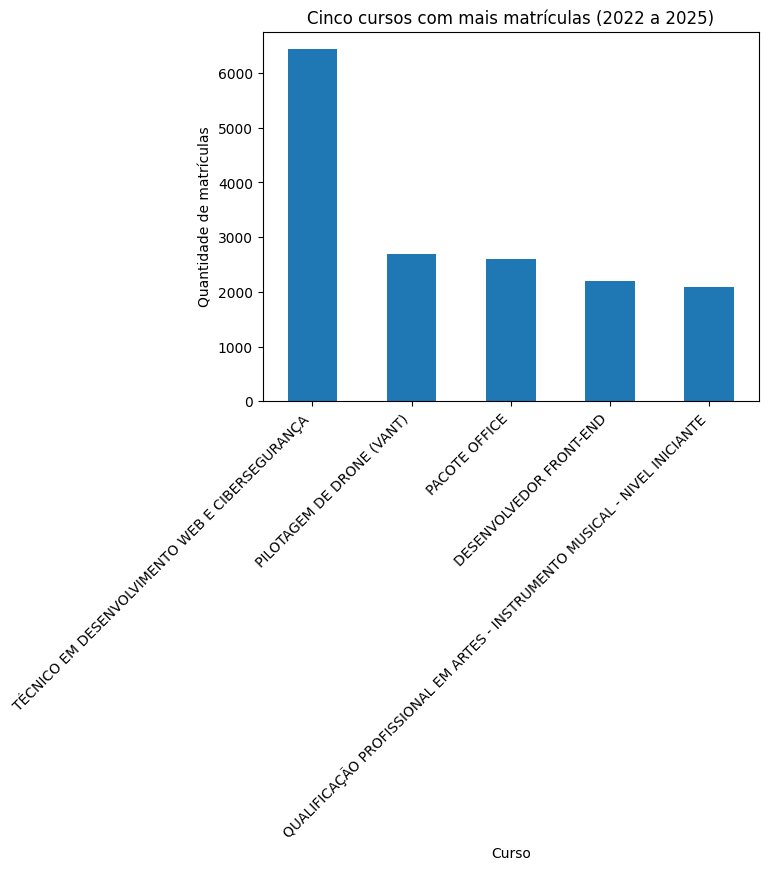

In [6]:
matriculas_curso.head(5).plot(kind="bar")
plt.title("Cinco cursos com mais matrículas (2022 a 2025)")
plt.xlabel("Curso")
plt.ylabel("Quantidade de matrículas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretação:** observe o primeiro curso da tabela para identificar o curso com mais matrículas. A tabela de categorias mostra qual categoria reúne mais matrículas.

**Próxima pergunta:** os cursos com mais matrículas também possuem maior ocupação das vagas?

## 8. Análise 2 — Qual escola possui mais e menos matrículas?

**Pergunta:** Como as matrículas estão distribuídas entre as escolas?

In [7]:
matriculas_escola = (
    dados_periodo.groupby("escola")["matriculas_turma"]
    .sum()
    .sort_values(ascending=False)
)

print("Cinco escolas com mais matrículas:")
display(matriculas_escola.head(5))

print("Cinco escolas com menos matrículas:")
display(matriculas_escola.tail(5))

Cinco escolas com mais matrículas:


,matriculas_turma
escola,
EM ARTES BASILEU FRANÇA,35163
LUIZ RASSI,14706
JOSÉ LUIZ BITTENCOURT,13078
SARAH LUÍSA LEMOS KUBITSCHEK DE OLIVEIRA,12683
PAULO RENATO DE SOUZA,5976


Cinco escolas com menos matrículas:


,matriculas_turma
escola,
UDEPI RIO VERDE (JLB),195
PRONATEC - APARECIDA,159
UDEPI ITUMBIARA (ABF),90
UDEPI MOSSÂMEDES (JLB),36
PRONATEC - SECTI,6


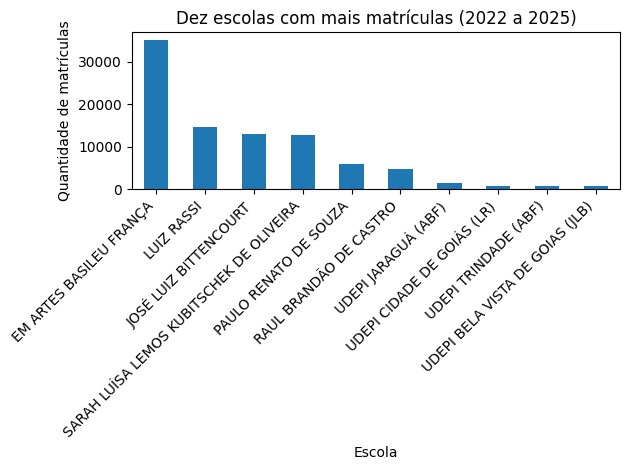

In [8]:
matriculas_escola.head(10).plot(kind="bar")
plt.title("Dez escolas com mais matrículas (2022 a 2025)")
plt.xlabel("Escola")
plt.ylabel("Quantidade de matrículas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretação:** a primeira linha da tabela indica a escola com mais matrículas. As últimas linhas mostram as escolas com os menores totais dentro da lista ordenada.

**Próxima pergunta:** as escolas com menos matrículas também oferecem menos vagas ou têm menor ocupação?

## 9. Análise 3 — Qual é a taxa de ocupação das vagas?

**Pergunta:** Qual é a relação entre o total de matrículas e o total de vagas? Em quais cursos a ocupação é menor?

A taxa será calculada assim: total de matrículas dividido pelo total de vagas, multiplicado por 100.

In [9]:
total_vagas = dados_periodo["qtde_vagas"].sum()
total_matriculas = dados_periodo["matriculas_turma"].sum()

if total_vagas > 0:
    taxa_ocupacao = total_matriculas / total_vagas * 100
else:
    taxa_ocupacao = 0

print("Total de vagas:", total_vagas)
print("Total de matrículas:", total_matriculas)
print(f"Taxa geral de ocupação: {taxa_ocupacao:.2f}%")

# Calcular ocupação por curso usando as somas, evitando calcular a média de percentuais
ocupacao_curso = dados_periodo.groupby("curso").agg(
    vagas=("qtde_vagas", "sum"),
    matriculas=("matriculas_turma", "sum")
)

ocupacao_curso["taxa_ocupacao_%"] = (
    ocupacao_curso["matriculas"] / ocupacao_curso["vagas"] * 100
)

print("Cursos com menor taxa de ocupação (considerando cursos com vagas):")
display(
    ocupacao_curso[ocupacao_curso["vagas"] > 0]
    .sort_values("taxa_ocupacao_%")
    .head(5)
)

print("Cursos com maior taxa de ocupação:")
display(
    ocupacao_curso[ocupacao_curso["vagas"] > 0]
    .sort_values("taxa_ocupacao_%", ascending=False)
    .head(5)
)

Total de vagas: 104111
Total de matrículas: 96307
Taxa geral de ocupação: 92.50%
Cursos com menor taxa de ocupação (considerando cursos com vagas):


,vagas,matriculas,taxa_ocupacao_%
curso,,,
VIOLA CLÁSSICA INICIANTE - ROJG,10,0,0.0
TÉCNICO DE NÍVEL MÉDIO EM SEGURANÇA DO TRABALHO - EAD - PRONATEC,450,0,0.0
TÉCNICO DE NÍVEL MÉDIO EM RECURSOS HUMANOS - EAD - PRONATEC,180,0,0.0
ESCADA LIVRE 3,1,0,0.0
ESCRITA DE RESUMOS,20,0,0.0


Cursos com maior taxa de ocupação:


,vagas,matriculas,taxa_ocupacao_%
curso,,,
SUPERIOR EM PRODUÇÃO CÊNICA REOFERTA,4,8,200.000000
ACROBACIA DE SOLO IV,12,16,133.333333
SUPERIOR DE TECNOLOGIA EM PRODUÇÃO CÊNICA,1368,1673,122.295322
MACRAMÊ II - DECORAÇÃO COM MANDALAS FOLHAS E PENAS EM MACRAMÊ,30,36,120.000000
BORDADO TRADICIONAL I,20,24,120.000000


/tmp/ipykernel_1062/340561727.py:12: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


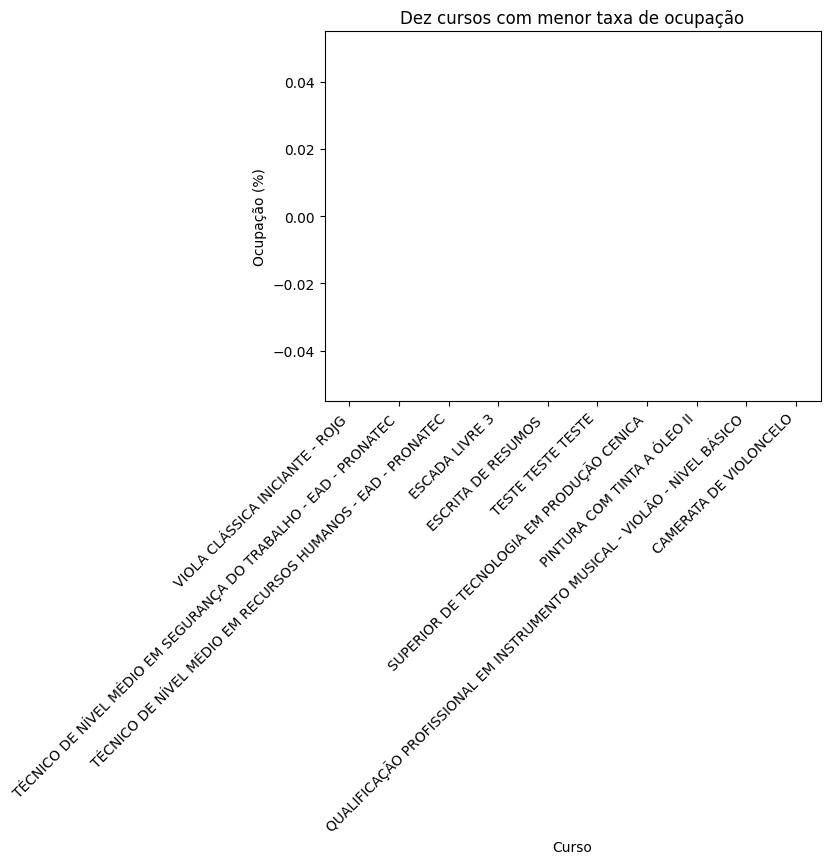

In [10]:
ocupacao_grafico = (
    ocupacao_curso[ocupacao_curso["vagas"] > 0]
    .sort_values("taxa_ocupacao_%")
    .head(10)
)

ocupacao_grafico["taxa_ocupacao_%"].plot(kind="bar")
plt.title("Dez cursos com menor taxa de ocupação")
plt.xlabel("Curso")
plt.ylabel("Ocupação (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretação:** uma taxa de 100% significa que o número de matrículas é igual ao número de vagas. Valores abaixo de 100% indicam que as matrículas somadas são menores que as vagas somadas.

**Próxima pergunta:** a ocupação muda de acordo com o turno e a modalidade?

## 10. Análise 4 — Existe diferença entre turnos e modalidades?

**Pergunta:** Como as vagas e matrículas se distribuem por turno e modalidade? Qual é a taxa de ocupação em cada grupo?

In [11]:
ocupacao_turno = dados_periodo.groupby("turno").agg(
    vagas=("qtde_vagas", "sum"),
    matriculas=("matriculas_turma", "sum"),
    turmas=("id_turma", "nunique")
)
ocupacao_turno["taxa_ocupacao_%"] = ocupacao_turno["matriculas"] / ocupacao_turno["vagas"] * 100

print("Resultado por turno:")
display(ocupacao_turno.sort_values("taxa_ocupacao_%", ascending=False))

ocupacao_modalidade = dados_periodo.groupby("modalidade").agg(
    vagas=("qtde_vagas", "sum"),
    matriculas=("matriculas_turma", "sum"),
    turmas=("id_turma", "nunique")
)
ocupacao_modalidade["taxa_ocupacao_%"] = ocupacao_modalidade["matriculas"] / ocupacao_modalidade["vagas"] * 100

print("Resultado por modalidade:")
display(ocupacao_modalidade.sort_values("taxa_ocupacao_%", ascending=False))

Resultado por turno:


,vagas,matriculas,turmas,taxa_ocupacao_%
turno,,,,
NOTURNO,37966,36730,943,96.744456
INTEGRAL,21248,19400,258,91.302711
VESPERTINO,31270,28115,858,89.910457
MATUTINO,13627,12062,469,88.515447


Resultado por modalidade:


,vagas,matriculas,turmas,taxa_ocupacao_%
modalidade,,,,
PRESENCIAL,97012,90243,2454,93.022513
EAD,7099,6064,74,85.420482


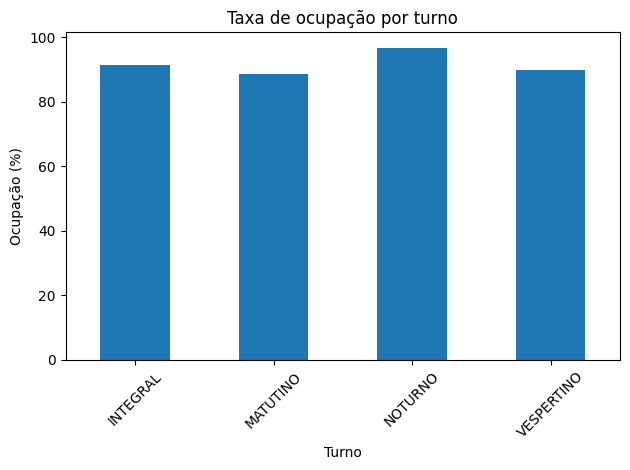

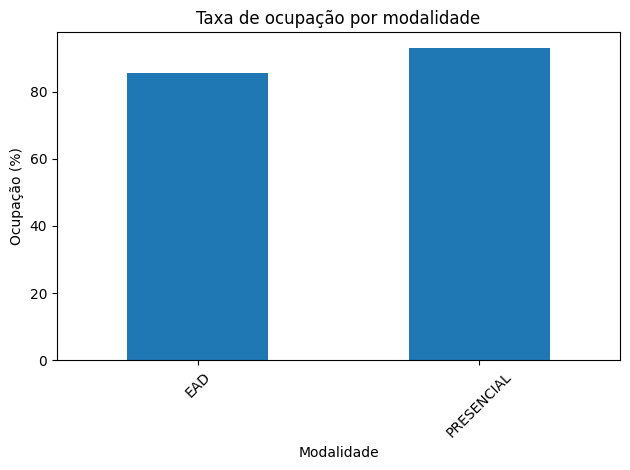

In [12]:
ocupacao_turno["taxa_ocupacao_%"].plot(kind="bar")
plt.title("Taxa de ocupação por turno")
plt.xlabel("Turno")
plt.ylabel("Ocupação (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

ocupacao_modalidade["taxa_ocupacao_%"].plot(kind="bar")
plt.title("Taxa de ocupação por modalidade")
plt.xlabel("Modalidade")
plt.ylabel("Ocupação (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretação:** compare as taxas calculadas nas tabelas. O turno ou a modalidade com maior percentual apresenta maior ocupação relativa das vagas.

**Próxima pergunta:** o número de turmas e matrículas cresceu ou diminuiu entre 2022 e 2025?

## 11. Análise 5 — Como turmas e matrículas mudaram ao longo dos anos?

**Pergunta:** Como variaram a quantidade de turmas, vagas e matrículas por ano? Qual categoria apresentou maior crescimento de matrículas entre 2022 e 2025?

In [13]:
resumo_ano = dados_periodo.groupby("ano").agg(
    turmas=("id_turma", "nunique"),
    vagas=("qtde_vagas", "sum"),
    matriculas=("matriculas_turma", "sum")
).sort_index()

print("Turmas, vagas e matrículas por ano:")
display(resumo_ano)

Turmas, vagas e matrículas por ano:


,turmas,vagas,matriculas
ano,,,
2022,606,25160,22119
2023,690,25827,24362
2024,506,28568,26583
2025,726,24556,23243


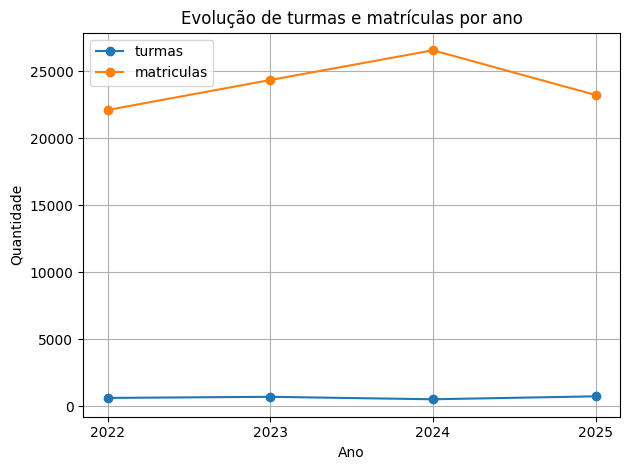

In [14]:
resumo_ano[["turmas", "matriculas"]].plot(kind="line", marker="o")
plt.title("Evolução de turmas e matrículas por ano")
plt.xlabel("Ano")
plt.ylabel("Quantidade")
plt.xticks(resumo_ano.index)
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
# Comparar matrículas por categoria entre o primeiro e o último ano do período
matriculas_categoria_ano = dados_periodo.pivot_table(
    index="categoria",
    columns="ano",
    values="matriculas_turma",
    aggfunc="sum",
    fill_value=0
)

display(matriculas_categoria_ano)

if 2022 in matriculas_categoria_ano.columns and 2025 in matriculas_categoria_ano.columns:
    matriculas_categoria_ano["crescimento_matriculas"] = (
        matriculas_categoria_ano[2025] - matriculas_categoria_ano[2022]
    )
    print("Categorias ordenadas pelo crescimento em número de matrículas (2022 a 2025):")
    display(matriculas_categoria_ano.sort_values("crescimento_matriculas", ascending=False))
else:
    print("Não foi possível comparar 2022 e 2025. Confira se os dois anos existem nos dados filtrados.")

ano,2022,2023,2024,2025
categoria,,,,
Capacitação,6536,8877,5415,10035
Graduação,383,678,384,236
Qualificação,11260,9925,10480,7921
Técnico,3940,4882,10304,5051


Categorias ordenadas pelo crescimento em número de matrículas (2022 a 2025):


ano,2022,2023,2024,2025,crescimento_matriculas
categoria,,,,,
Capacitação,6536,8877,5415,10035,3499
Técnico,3940,4882,10304,5051,1111
Graduação,383,678,384,236,-147
Qualificação,11260,9925,10480,7921,-3339


**Interpretação:** observe se a linha de matrículas sobe ou desce com o passar dos anos. Na tabela por categoria, o maior valor em `crescimento_matriculas` representa o maior aumento absoluto de matrículas entre 2022 e 2025. Um valor negativo indica redução.

**Limitação:** esta análise usa o ano extraído de `data_inicio`, porque o CSV fornecido não possui a coluna `semestre` descrita no planejamento.

## 12. Gráficos exploratórios
Além dos gráficos das análises anteriores, vamos observar a distribuição das turmas por status e por categoria.

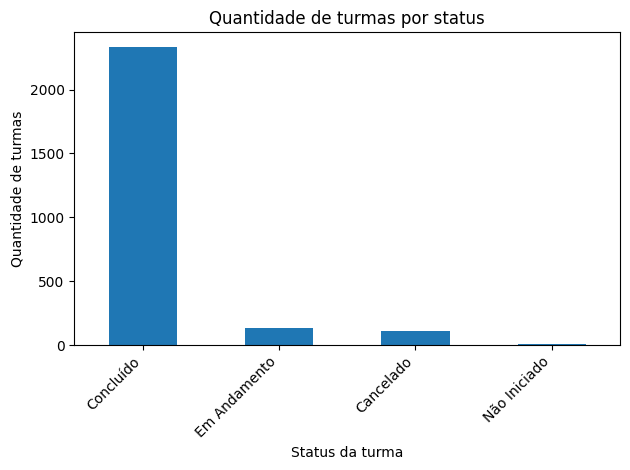

,id_turma
status_turma,
Concluído,2332
Em Andamento,131
Cancelado,107
Não Iniciado,11


In [16]:
# Quantidade de turmas por status
turmas_status = dados_periodo.groupby("status_turma")["id_turma"].nunique().sort_values(ascending=False)

turmas_status.plot(kind="bar")
plt.title("Quantidade de turmas por status")
plt.xlabel("Status da turma")
plt.ylabel("Quantidade de turmas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(turmas_status)

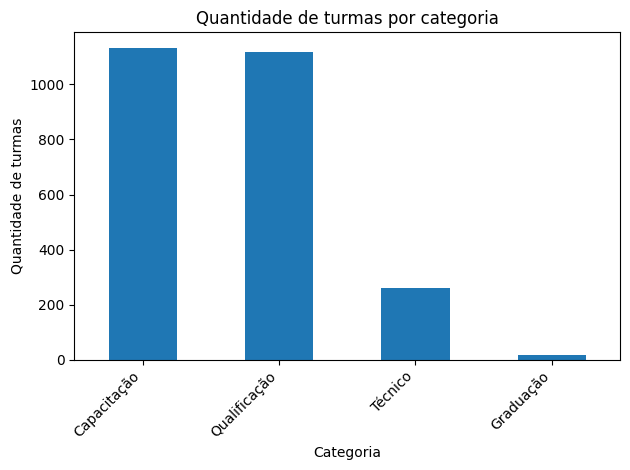

,id_turma
categoria,
Capacitação,1132
Qualificação,1119
Técnico,260
Graduação,17


In [17]:
# Quantidade de turmas por categoria
turmas_categoria = dados_periodo.groupby("categoria")["id_turma"].nunique().sort_values(ascending=False)

turmas_categoria.plot(kind="bar")
plt.title("Quantidade de turmas por categoria")
plt.xlabel("Categoria")
plt.ylabel("Quantidade de turmas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(turmas_categoria)

## 13. Principais descobertas

Execute as células e use os resultados para completar este resumo. O código abaixo apresenta automaticamente alguns dos principais números calculados na base.

In [18]:
if len(dados_periodo) > 0:
    curso_maior = matriculas_curso.index[0] if len(matriculas_curso) else "Não identificado"
    escola_maior = matriculas_escola.index[0] if len(matriculas_escola) else "Não identificada"
    categoria_maior = matriculas_categoria.index[0] if len(matriculas_categoria) else "Não identificada"

    print("PRINCIPAIS DESCOBERTAS")
    print("----------------------")
    print(f"Registros analisados de 2022 a 2025: {len(dados_periodo)}")
    print(f"Total de turmas únicas: {dados_periodo['id_turma'].nunique()}")
    print(f"Total de vagas: {total_vagas}")
    print(f"Total de matrículas: {total_matriculas}")
    print(f"Taxa geral de ocupação: {taxa_ocupacao:.2f}%")
    print(f"Curso com mais matrículas: {curso_maior}")
    print(f"Escola com mais matrículas: {escola_maior}")
    print(f"Categoria com mais matrículas: {categoria_maior}")
else:
    print("Não há registros no período de 2022 a 2025. Confira a coluna data_inicio.")

PRINCIPAIS DESCOBERTAS
----------------------
Registros analisados de 2022 a 2025: 4432
Total de turmas únicas: 2528
Total de vagas: 104111
Total de matrículas: 96307
Taxa geral de ocupação: 92.50%
Curso com mais matrículas: TÉCNICO EM DESENVOLVIMENTO WEB E CIBERSEGURANÇA
Escola com mais matrículas: EM ARTES BASILEU FRANÇA
Categoria com mais matrículas: Qualificação


## 14. Primeiros insights

Os insights são interpretações iniciais dos resultados, não conclusões definitivas.

1. **Oferta e procura:**
 Comparar o total de vagas com o total de matrículas ajuda a perceber se a oferta está sendo preenchida.  

2. **Cursos mais procurados:**
Os cursos com mais matrículas podem ajudar a identificar áreas de maior procura.

3. **Diferenças entre escolas:**
Comparar os totais por escola pode indicar onde há maior volume de matrículas; isso não significa, por si só, melhor desempenho, pois a quantidade de vagas também pode ser diferente.

4. **Turno e modalidade:**
Diferenças nas taxas de ocupação podem ajudar a levantar perguntas para uma investigação futura.

5. **Mudança ao longo do tempo:** a comparação de 2022 com 2025 mostra a variação anual dos registros de início de turma, usando `data_inicio` como referência temporal.

**Conclusão inicial:** os resultados deste notebook ajudam a organizar uma primeira visão da oferta de turmas, vagas e matrículas das Escolas do Futuro de Goiás.